In [30]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt


In [19]:
df=pd.read_csv(r"C:\Users\Tejaswini\Downloads\archive (1)\winequality-red.csv")

In [20]:
print("Shape ")
print(df.shape)

Shape 
(1599, 12)


In [21]:
print("First 5 rows")
print(df.head())

First 5 rows
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      

In [22]:
print("Colums Names")
print(df.columns)

Colums Names
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')


In [24]:
print("Missing Values")
print(df.isnull().sum())

Missing Values
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [28]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler


x = df.drop("quality", axis=1)
y = df["quality"]

# Min-Max Normalization
normalizer = MinMaxScaler()
x_normalized = normalizer.fit_transform(x)

print("Normalized data (first 5 rows):")
print(pd.DataFrame(x_normalized, columns=x.columns).head().round(3))

# Standardization
standardizer = StandardScaler()
x_standardized = standardizer.fit_transform(x)

print("Standardized data (first 5 rows):")
print(pd.DataFrame(x_standardized, columns=x.columns).head().round(3))


Normalized data (first 5 rows):
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0          0.248             0.397         0.00           0.068      0.107   
1          0.283             0.521         0.00           0.116      0.144   
2          0.283             0.438         0.04           0.096      0.134   
3          0.584             0.110         0.56           0.068      0.105   
4          0.248             0.397         0.00           0.068      0.107   

   free sulfur dioxide  total sulfur dioxide  density     pH  sulphates  \
0                0.141                 0.099    0.568  0.606      0.138   
1                0.338                 0.216    0.494  0.362      0.210   
2                0.197                 0.170    0.509  0.409      0.192   
3                0.225                 0.191    0.582  0.331      0.150   
4                0.141                 0.099    0.568  0.606      0.138   

   alcohol  
0    0.154  
1    0.215  
2    0.21

In [32]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
x_pca=pca.fit_transform(x_standardized)
print("PCA output first 5 rows):")
print(pd.DataFrame(x_pca,columns=["PC1","PC2"]).head().round(3))
print("Original number of features:",x.shape[1])
print("Reduced number of features:",x_pca.shape[1])

PCA output first 5 rows):
     PC1    PC2
0 -1.620  0.451
1 -0.799  1.857
2 -0.748  0.882
3  2.358 -0.270
4 -1.620  0.451
Original number of features: 11
Reduced number of features: 2


In [33]:
print("Variance retained by each component:")
print(pca.explained_variance_ratio_.round(4))
print("Total variance retained:",round(sum(pca.explained_variance_ratio_)*100,2),"%")

Variance retained by each component:
[0.2817 0.1751]
Total variance retained: 45.68 %


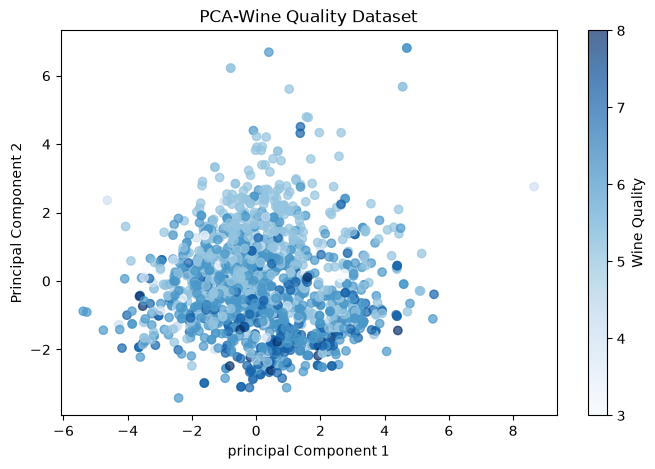

In [39]:
plt.figure(figsize=(8,5))
plt.scatter(x_pca[:,0],x_pca[:,1],c=y,cmap="Blues",alpha=0.7)
plt.xlabel("principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA-Wine Quality Dataset")
plt.colorbar(label="Wine Quality")
plt.show()